<a href="https://colab.research.google.com/github/Shadid123/Digital-Image-Processing/blob/main/Assignment%203/3.4_Histogram_Equalization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

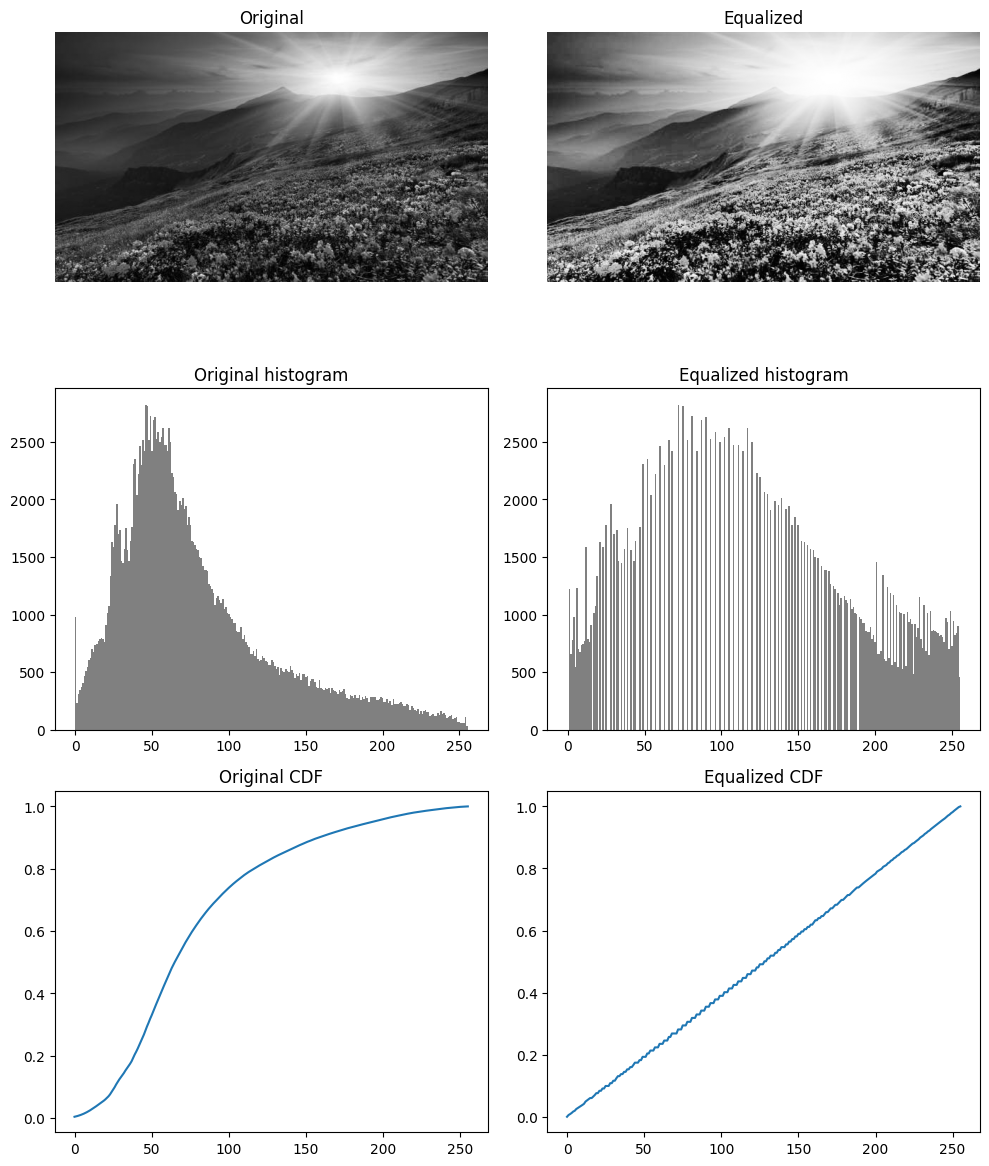

In [ ]:
import numpy as np                  # tool for working with numbers and lists
import cv2                          # tool for reading the image
import matplotlib.pyplot as plt     # tool for drawing graphs

img = cv2.imread("/content/input.jpg", cv2.IMREAD_GRAYSCALE)   # open the picture in black and white
L = 256                             # 256 brightness values (0 to 255)
M, N = img.shape                    # height and width of the picture

# STEP 1: count pixels (histogram)
hist = np.zeros(L)                  # 256 empty boxes
for v in img.ravel():               # take every pixel one by one
    hist[v] += 1                    # count it in the box of its brightness

# STEP 2: fractions and running total
pdf = hist / (M * N)                # counts become fractions
cdf = np.cumsum(pdf)                # running total of the fractions

# STEP 3: make the rule for new brightness
new_value = np.round(255 * cdf).astype(np.uint8)   # each old brightness gets a new brightness

# STEP 4: change every pixel using the rule
equalized = new_value[img]          # look up the new brightness for every pixel of the picture

# STEP 5: count pixels again, this time for the new picture
hist_eq = np.zeros(L)               # 256 new empty boxes
for v in equalized.ravel():         # take every pixel of the new picture
    hist_eq[v] += 1                 # count it
cdf_eq = np.cumsum(hist_eq / (M * N))   # running total for the new picture

# STEP 6: show before and after
plt.figure(figsize=(10, 12))        # make a big drawing area for 6 pictures

plt.subplot(3, 2, 1)                # row 1, left
plt.imshow(img, cmap='gray', vmin=0, vmax=255)   # show the old picture
plt.title('Original')               # label it
plt.axis('off')                     # hide the numbers around the picture

plt.subplot(3, 2, 2)                # row 1, right
plt.imshow(equalized, cmap='gray', vmin=0, vmax=255)   # show the new picture
plt.title('Equalized')              # label it
plt.axis('off')                     # hide the numbers around the picture

plt.subplot(3, 2, 3)                # row 2, left
plt.bar(np.arange(L), hist, width=1.0, color='gray')   # histogram of old picture
plt.title('Original histogram')     # label it

plt.subplot(3, 2, 4)                # row 2, right
plt.bar(np.arange(L), hist_eq, width=1.0, color='gray')   # histogram of new picture
plt.title('Equalized histogram')    # label it (should be more spread out)

plt.subplot(3, 2, 5)                # row 3, left
plt.plot(cdf)                       # running total of old picture
plt.title('Original CDF')           # label it

plt.subplot(3, 2, 6)                # row 3, right
plt.plot(cdf_eq)                    # running total of new picture
plt.title('Equalized CDF')          # label it (should be close to a straight line)

plt.tight_layout()                  # stop the graphs from overlapping
plt.show()                          # show everything